# Effective Scintillator Propagation Speed ($c_{\mathrm{scint}}$) Fitting & Systematic Uncertainty

This notebook illustrates the extraction of effective scintillation velocity $c_{\mathrm{scint}}$, its statistical error, and the **5-segment disjoint sub-range fitting** method used to evaluate systematic uncertainties following the PDG scale factor prescription.

### Methodology:
1. **Vertical Slice Extraction:** Slices along predicted track position $x_{\mathrm{pred}}$ of the 2D timing difference $\Delta t = t_0^{\mathrm{SF}} - t_{\mathrm{SiPM}}$ are fitted with localized Gaussians to obtain Most Probable Values (MPVs) and statistical fit errors.
2. **Global Linear Fit:** An unconstrained first-degree polynomial fit $\Delta t(x) = m\cdot x + q$ across the fiducial range $[-44.0, -8.0]\,\mathrm{cm}$ gives:
   $$c_{\mathrm{scint}} = \frac{\mathrm{side\_sign}}{m}, \quad \Delta c_{\mathrm{stat}} = \frac{\sigma_m}{m^2}$$
3. **5-Segment Systematic Evaluation:** The fiducial interval is divided into 5 equal, disjoint sub-segments. Each segment is fitted independently with a linear function. The scatter of the resulting speeds $c_s \pm \sigma_s$ relative to their weighted mean yields the PDG scale factor $S = \sqrt{\chi^2_{\mathrm{red}}}$ and systematic uncertainty:
   $$\Delta c_{\mathrm{syst}} = \sqrt{\sigma_{\mathrm{final}}^2 - \sigma_0^2} = \sigma_0 \sqrt{\max(0, S^2 - 1)}$$

We analyze channel **`20001_11`** (US bar 1, SiPM 11) using the **SciFi (SF) reference time** from `/eos/user/i/idioniso/Timing/cscint/fits_root/run5119.root`.


In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import ROOT

try:
    import ddfUtils.mpl_styling as dms
    has_dms = True
except ImportError:
    has_dms = False

# PyROOT batch configuration
ROOT.gROOT.SetBatch(True)
ROOT.gErrorIgnoreLevel = ROOT.kError

# Styling parameters
plt.rcParams.update({
    "font.size": 13,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 11,
    "figure.titlesize": 16,
})
print("Environment and PyROOT configured.")


Environment and PyROOT configured.


In [2]:
root_path = "/eos/user/i/idioniso/Timing/cscint/fits_root/run5119.root"
ch_name = "20001_11"
ref = "SF"
detID = 20001
sipm = 11

fit_min, fit_max = -44.0, -8.0
min_slice_entries = 15
side_sign = 1.0 if sipm < 8 else -1.0

f = ROOT.TFile.Open(root_path)
assert f and not f.IsZombie(), f"Cannot open {root_path}"

h2 = f.Get(f"{ch_name}/dt-{ref}")
assert h2 is not None, f"Histogram {ch_name}/dt-{ref} not found"

# Extract 2D histogram data for contour/heatmap plotting
nbins_x = h2.GetNbinsX()
nbins_y = h2.GetNbinsY()
x_edges = np.array([h2.GetXaxis().GetBinLowEdge(i) for i in range(1, nbins_x + 2)])
y_edges = np.array([h2.GetYaxis().GetBinLowEdge(i) for i in range(1, nbins_y + 2)])
h2_counts = np.zeros((nbins_y, nbins_x))

for ix in range(1, nbins_x + 1):
    for iy in range(1, nbins_y + 1):
        h2_counts[iy - 1, ix - 1] = h2.GetBinContent(ix, iy)

# Perform slice Gaussian fits
slices_x = []
slices_y = []
slices_ey = []
slice_details = []

fg = ROOT.TF1("fg_temp", "gaus", -10, 10, ROOT.TF1.EAddToList.kNo)

for bx in range(1, nbins_x + 1):
    x_val = h2.GetXaxis().GetBinCenter(bx)
    if x_val < fit_min or x_val > fit_max:
        continue
    py = h2.ProjectionY(f"h_py_{bx}", bx, bx)
    if py.GetEntries() < min_slice_entries:
        continue
    
    max_bin = py.GetMaximumBin()
    mode = py.GetBinCenter(max_bin)
    rms = py.GetRMS()
    fit_range = max(0.8, min(1.8, 1.5 * rms))
    
    fg.SetRange(mode - fit_range, mode + fit_range)
    fg.SetParameters(py.GetBinContent(max_bin), mode, max(0.3, rms))
    res_g = py.Fit(fg, "QNS0")
    
    mpv = None
    mpv_err = None
    if int(res_g) == 0 and 0 < fg.GetParError(1) < 2.5:
        p1 = fg.GetParameter(1)
        if mode - 2.5 < p1 < mode + 2.5:
            mpv = p1
            mpv_err = fg.GetParError(1)
    if mpv is None:
        mpv = mode
        mpv_err = py.GetBinWidth(max_bin) / np.sqrt(12.0)
        
    slices_x.append(x_val)
    slices_y.append(mpv)
    slices_ey.append(mpv_err)
    slice_details.append({
        "bx": bx,
        "x": x_val,
        "mpv": mpv,
        "mpv_err": mpv_err,
        "sigma": abs(fg.GetParameter(2)),
        "entries": py.GetEntries(),
    })

slices_x = np.array(slices_x)
slices_y = np.array(slices_y)
slices_ey = np.array(slices_ey)

print(f"Extracted {len(slices_x)} vertical slice MPVs in [{fit_min}, {fit_max}] cm.")


Extracted 36 vertical slice MPVs in [-44.0, -8.0] cm.


In [3]:
# Build TGraphErrors for fitting
gr = ROOT.TGraphErrors(len(slices_x), slices_x, slices_y, np.zeros(len(slices_x)), slices_ey)

# 1. Global Fit
func_global = ROOT.TF1("fit_global", "pol1", fit_min, fit_max)
gr.Fit(func_global, "QNS0R")

global_slope = func_global.GetParameter(1)
global_slope_err = func_global.GetParError(1)
global_intercept = func_global.GetParameter(0)
global_intercept_err = func_global.GetParError(0)
global_chi2 = func_global.GetChisquare()
global_ndf = max(1, func_global.GetNDF())
global_c = side_sign / global_slope
global_delta_c = abs(global_slope_err / (global_slope ** 2))

# 2. Five-Segment Sub-range Fits
n_segments = 5
total_span = fit_max - fit_min
seg_width = total_span / n_segments

subrange_fits = []
seg_results = []

colors_seg = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3", "#ff7f00"]

for s_idx in range(n_segments):
    x_low = fit_min + s_idx * seg_width
    x_high = fit_min + (s_idx + 1) * seg_width
    mask = (slices_x >= x_low) & (slices_x <= x_high)
    n_pts = np.sum(mask)
    
    seg_func = ROOT.TF1(f"seg_func_{s_idx}", "pol1", x_low, x_high)
    gr.Fit(seg_func, "QNS0R")
    
    m_s = seg_func.GetParameter(1)
    m_s_err = seg_func.GetParError(1)
    q_s = seg_func.GetParameter(0)
    q_s_err = seg_func.GetParError(0)
    chi2_s = seg_func.GetChisquare()
    ndf_s = max(1, seg_func.GetNDF())
    
    c_s = side_sign / m_s
    c_s_err = abs(m_s_err / (m_s ** 2))
    
    subrange_fits.append((float(c_s), float(c_s_err)))
    seg_results.append({
        "idx": s_idx,
        "x_low": x_low,
        "x_high": x_high,
        "n_pts": int(n_pts),
        "slope": m_s,
        "slope_err": m_s_err,
        "intercept": q_s,
        "intercept_err": q_s_err,
        "c_scint": c_s,
        "c_scint_err": c_s_err,
        "chi2": chi2_s,
        "ndf": ndf_s,
        "color": colors_seg[s_idx]
    })

# PDG Scale Factor Systematic Calculation
segments_arr = np.array(subrange_fits, dtype=float)
c_vals = segments_arr[:, 0]
sig_vals = segments_arr[:, 1]
w_vals = 1.0 / (sig_vals ** 2)
c_mu_pdg = float(np.sum(w_vals * c_vals) / np.sum(w_vals))
sigma_0 = float(1.0 / np.sqrt(np.sum(w_vals)))
chi2_sub = float(np.sum(w_vals * (c_vals - c_mu_pdg) ** 2))
ndf_sub = max(1, len(c_vals) - 1)
chi2_red_sub = chi2_sub / ndf_sub
s_scale = float(np.sqrt(chi2_red_sub)) if chi2_red_sub > 1.0 else 1.0
sigma_final = s_scale * sigma_0
delta_c_syst = float(np.sqrt(max(0.0, sigma_final ** 2 - sigma_0 ** 2)))
delta_c_tot = float(np.sqrt(global_delta_c ** 2 + delta_c_syst ** 2))

print(f"Global Fit: c_scint = {global_c:.2f} +/- {global_delta_c:.2f} (stat) +/- {delta_c_syst:.2f} (syst) cm/ns")
print(f"Total Uncertainty: c_scint = {global_c:.2f} +/- {delta_c_tot:.2f} cm/ns (chi2/ndf = {global_chi2:.1f}/{global_ndf} = {global_chi2/global_ndf:.2f})")
print(f"Sub-segment PDG Scale Factor: S = {s_scale:.2f}, chi2_red = {chi2_red_sub:.2f}")


Global Fit: c_scint = 13.72 +/- 0.03 (stat) +/- 1.76 (syst) cm/ns
Total Uncertainty: c_scint = 13.72 +/- 1.76 cm/ns (chi2/ndf = 3763.5/34 = 110.69)
Sub-segment PDG Scale Factor: S = 13.38, chi2_red = 179.01


In [4]:
import pandas as pd
df_segs = pd.DataFrame([
    {
        "Segment": f"Seg {s['idx'] + 1}",
        "x Range [cm]": f"[{s['x_low']:.1f}, {s['x_high']:.1f}]",
        "Points": s["n_pts"],
        "Slope [ns/cm]": f"{s['slope']:.4f} +/- {s['slope_err']:.4f}",
        "c_scint [cm/ns]": f"{s['c_scint']:.2f} +/- {s['c_scint_err']:.2f}",
        "chi2/ndf": f"{s['chi2']:.1f}/{s['ndf']} ({s['chi2']/s['ndf']:.2f})"
    }
    for s in seg_results
])
df_segs


,Segment,x Range [cm],Points,Slope [ns/cm],c_scint [cm/ns],chi2/ndf
0,Seg 1,"[-44.0, -36.8]",7,-0.0538 +/- 0.0021,18.60 +/- 0.71,8.5/5 (1.71)
1,Seg 2,"[-36.8, -29.6]",7,-0.0439 +/- 0.0021,22.79 +/- 1.09,3.3/5 (0.67)
2,Seg 3,"[-29.6, -22.4]",8,-0.0710 +/- 0.0018,14.08 +/- 0.35,8.4/6 (1.40)
3,Seg 4,"[-22.4, -15.2]",7,-0.1234 +/- 0.0023,8.10 +/- 0.15,54.0/5 (10.79)
4,Seg 5,"[-15.2, -8.0]",7,-0.0472 +/- 0.0021,21.19 +/- 0.96,4.7/5 (0.94)


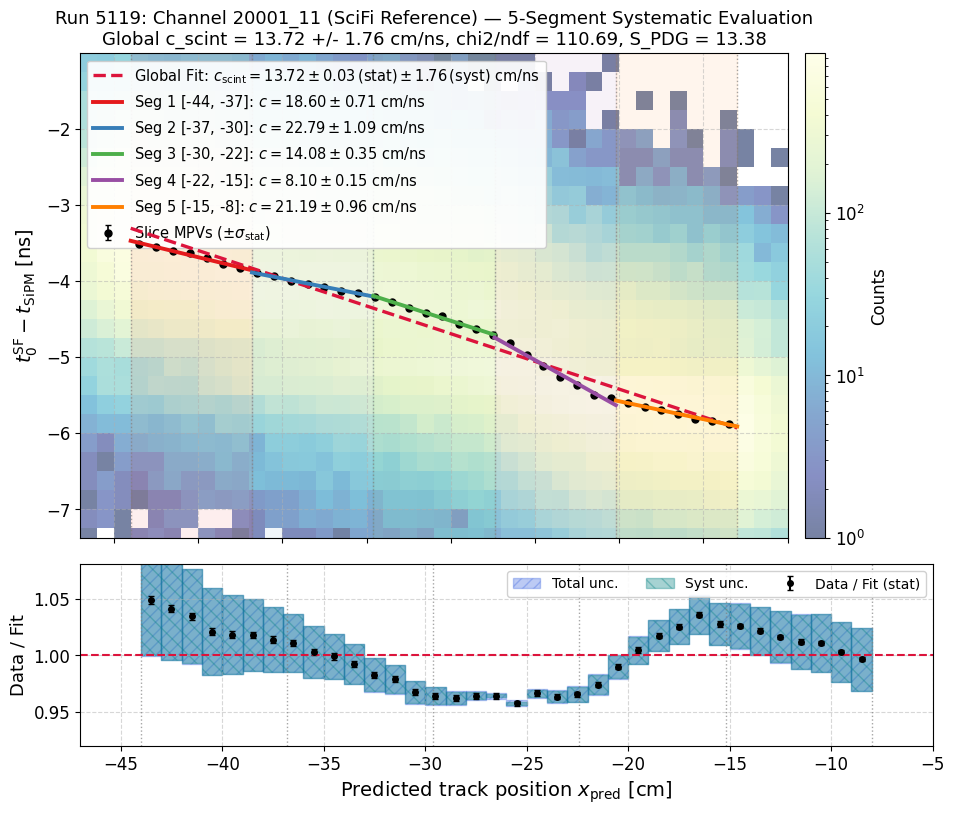

In [5]:
fig, (ax_main, ax_ratio) = plt.subplots(
    2, 1, figsize=(11, 9), gridspec_kw={"height_ratios": [3.2, 1.2], "hspace": 0.08}, sharex=True
)

# 1. 2D Distribution in background
norm_c = mcolors.LogNorm(vmin=max(1, np.percentile(h2_counts[h2_counts > 0], 5)), vmax=np.max(h2_counts))
pcol = ax_main.pcolormesh(x_edges, y_edges, h2_counts, cmap="YlGnBu_r", norm=norm_c, alpha=0.55, shading="auto")
cbar = fig.colorbar(pcol, ax=ax_main, pad=0.02, aspect=24)
cbar.set_label("Counts", fontsize=12)

# Shaded background bands for the 5 segments
for s in seg_results:
    ax_main.axvspan(s["x_low"], s["x_high"], alpha=0.07, color=s["color"], label="_nolegend_")
    ax_main.axvline(s["x_low"], color="gray", linestyle=":", linewidth=1.0, alpha=0.7)
    ax_ratio.axvline(s["x_low"], color="gray", linestyle=":", linewidth=1.0, alpha=0.7)
ax_main.axvline(fit_max, color="gray", linestyle=":", linewidth=1.0, alpha=0.7)
ax_ratio.axvline(fit_max, color="gray", linestyle=":", linewidth=1.0, alpha=0.7)

# 2. Slice MPV Data Points
ax_main.errorbar(
    slices_x, slices_y, yerr=slices_ey, fmt="o", color="black",
    markersize=5, capsize=2, elinewidth=1.2, label=r"Slice MPVs ($\pm \sigma_{\mathrm{stat}}$)", zorder=5
)

# 3. Global Fit Line
x_dense = np.linspace(fit_min, fit_max, 300)
y_global_dense = global_slope * x_dense + global_intercept
ax_main.plot(
    x_dense, y_global_dense, color="crimson", linewidth=2.4, linestyle="--",
    label=rf"Global Fit: $c_{{\mathrm{{scint}}}} = {global_c:.2f} \pm {global_delta_c:.2f}\,\mathrm{{(stat)}}\pm {delta_c_syst:.2f}\,\mathrm{{(syst)}}$ cm/ns",
    zorder=6
)

# 4. Five Disjoint Segment Fit Lines
for s in seg_results:
    x_seg = np.linspace(s["x_low"], s["x_high"], 50)
    y_seg = s["slope"] * x_seg + s["intercept"]
    ax_main.plot(
        x_seg, y_seg, color=s["color"], linewidth=2.8,
        label=rf"Seg {s['idx']+1} [{s['x_low']:.0f}, {s['x_high']:.0f}]: $c = {s['c_scint']:.2f} \pm {s['c_scint_err']:.2f}$ cm/ns",
        zorder=7
    )

ax_main.set_xlim(fit_min - 3.0, fit_max + 3.0)
y_span_min = np.min(slices_y) - 1.5
y_span_max = np.max(slices_y) + 2.5
ax_main.set_ylim(y_span_min, y_span_max)
ax_main.set_ylabel(r"$t_0^{\mathrm{SF}} - t_{\mathrm{SiPM}}$ [ns]", fontsize=14)
ax_main.set_title(
    f"Run 5119: Channel {ch_name} (SciFi Reference) — 5-Segment Systematic Evaluation\n"
    f"Global c_scint = {global_c:.2f} +/- {delta_c_tot:.2f} cm/ns, chi2/ndf = {global_chi2/global_ndf:.2f}, S_PDG = {s_scale:.2f}",
    fontsize=13
)
ax_main.grid(True, linestyle="--", alpha=0.5)
ax_main.legend(loc="upper left", framealpha=0.92, fontsize=10.5)

# --- Bottom Panel: Data / Fit Ratio ---
y_fit_at_slices = global_slope * slices_x + global_intercept
ratio = slices_y / y_fit_at_slices
ratio_err_stat = slices_ey / np.abs(y_fit_at_slices)

# Systematic uncertainty band point-by-point
sigma_m_syst = abs(delta_c_syst / (global_c ** 2)) if global_c > 0 else 0.0
x_mean = np.mean(slices_x)
sigma_syst_arr = np.abs(sigma_m_syst * (slices_x - x_mean))
ratio_err_syst = sigma_syst_arr / np.abs(y_fit_at_slices)
ratio_err_tot = np.sqrt(ratio_err_stat ** 2 + ratio_err_syst ** 2)

# Draw hatched bands
dx = 0.5
for i in range(len(slices_x)):
    xi = slices_x[i]
    ax_ratio.fill_between(
        [xi - dx, xi + dx],
        [ratio[i] - ratio_err_tot[i], ratio[i] - ratio_err_tot[i]],
        [ratio[i] + ratio_err_tot[i], ratio[i] + ratio_err_tot[i]],
        color="royalblue", alpha=0.35, hatch="///", label="Total unc." if i == 0 else ""
    )
    ax_ratio.fill_between(
        [xi - dx, xi + dx],
        [ratio[i] - ratio_err_syst[i], ratio[i] - ratio_err_syst[i]],
        [ratio[i] + ratio_err_syst[i], ratio[i] + ratio_err_syst[i]],
        color="teal", alpha=0.35, hatch="\\\\", label="Syst unc." if i == 0 else ""
    )

ax_ratio.errorbar(slices_x, ratio, yerr=ratio_err_stat, fmt="o", color="black", markersize=4, capsize=2, label="Data / Fit (stat)")
ax_ratio.axhline(1.0, color="crimson", linestyle="--", linewidth=1.5)

ax_ratio.set_ylim(0.92, 1.08)
ax_ratio.set_xlabel(r"Predicted track position $x_{\mathrm{pred}}$ [cm]", fontsize=14)
ax_ratio.set_ylabel("Data / Fit", fontsize=13)
ax_ratio.grid(True, linestyle="--", alpha=0.5)
ax_ratio.legend(loc="upper right", ncol=3, framealpha=0.9, fontsize=10)

plt.show()


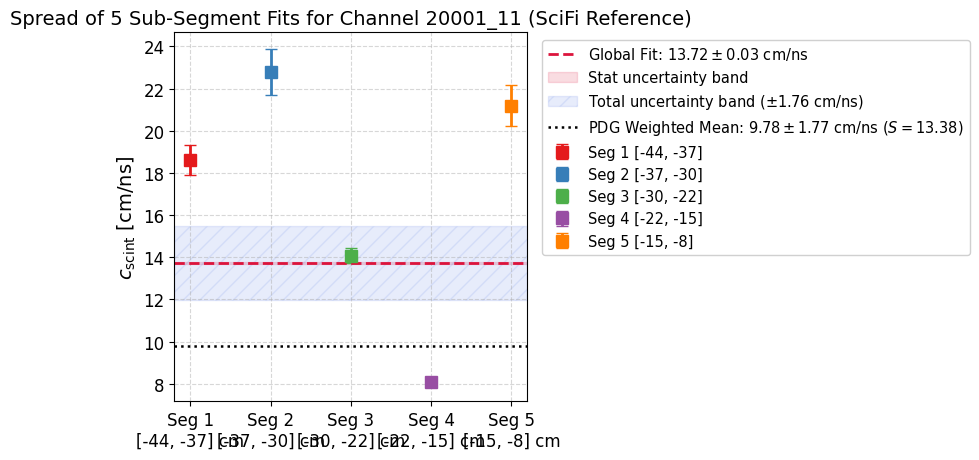

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.8))

seg_x = np.arange(1, n_segments + 1)
c_sub_vals = [s["c_scint"] for s in seg_results]
c_sub_errs = [s["c_scint_err"] for s in seg_results]

# Plot each segment
for i in range(n_segments):
    ax.errorbar(
        seg_x[i], c_sub_vals[i], yerr=c_sub_errs[i],
        fmt="s", color=seg_results[i]["color"], ecolor=seg_results[i]["color"],
        capsize=4, elinewidth=2, markersize=8,
        label=rf"Seg {i+1} [{seg_results[i]['x_low']:.0f}, {seg_results[i]['x_high']:.0f}]"
    )

# Band for Global Fit
ax.axhline(global_c, color="crimson", linestyle="--", linewidth=2.0, label=rf"Global Fit: ${global_c:.2f} \pm {global_delta_c:.2f}$ cm/ns")
ax.axhspan(global_c - global_delta_c, global_c + global_delta_c, color="crimson", alpha=0.15, label="Stat uncertainty band")
ax.axhspan(global_c - delta_c_tot, global_c + delta_c_tot, color="royalblue", alpha=0.12, hatch="//", label=rf"Total uncertainty band ($\pm {delta_c_tot:.2f}$ cm/ns)")

# Weighted mean of segments
ax.axhline(c_mu_pdg, color="black", linestyle=":", linewidth=1.8, label=rf"PDG Weighted Mean: ${c_mu_pdg:.2f} \pm {sigma_final:.2f}$ cm/ns ($S = {s_scale:.2f}$)")

ax.set_xticks(seg_x)
ax.set_xticklabels([f"Seg {i+1}\n[{s['x_low']:.0f}, {s['x_high']:.0f}] cm" for i, s in enumerate(seg_results)])
ax.set_ylabel(r"$c_{\mathrm{scint}}$ [cm/ns]", fontsize=14)
ax.set_title(rf"Spread of 5 Sub-Segment Fits for Channel {ch_name} (SciFi Reference)", fontsize=14)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", framealpha=0.92, fontsize=10.5)

plt.tight_layout()
plt.show()
